# **Учебный кейс: анализ корреляции**

*Шаблон для выполнения задания*

## **Описание данных**

[Ссылка](https://www.kaggle.com/datasets/lainguyn123/student-performance-factors?utm_source=chatgpt.com$0) на данные.

В этом задании используется датасет Student Performance, содержащий информацию о факторах, которые могут влиять на успеваемость студентов.  

В данных представлены сведения о времени подготовки, посещаемости занятий, сне, физической активности, дополнительных занятиях и итоговых результатах экзамена.  

Каждая строка таблицы соответствует отдельному студенту, а признаки отражают различные аспекты учебного процесса и образа жизни.  

В рамках задания будут использоваться следующие числовые признаки:  

* `Hours_Studied` — количество часов подготовки в неделю;  
* `Attendance` — посещаемость занятий в процентах;  
* `Sleep_Hours` — среднее количество часов сна;  
* `Previous_Scores` — результаты предыдущих экзаменов;  
* `Tutoring_Sessions` — количество дополнительных занятий;  
* `Physical_Activity` — количество часов физической активности;  
* `Exam_Score` — итоговый балл экзамена.  

### **1. Импорт библиотек**

Импортируйте необходимые для работы библиотеки: `pandas`, `matplotlib.pyplot`, `seaborn`, `scipy.stats`.

In [9]:
# Ваш код здесь

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

# настройки отображения графиков
sns.set_theme(style="whitegrid")

### **2. Загрузка данных**

Скачайте датасет Student Performance и загрузите CSV-файл вручную. Загрузите датасет в формате CSV с помощью функции `pd.read_csv()`.

In [38]:
# Ваш код здесь
df_2 = pd.read_csv('StudentPerformanceFactors.csv')
# Ваш код здесь: выведите первые строки

df_2.head()

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


*Ваш вывод по первичному анализу данных (структура, пропуски, типы данных):*


In [36]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   Hours_Studied      6607 non-null   int64
 1   Attendance         6607 non-null   int64
 2   Sleep_Hours        6607 non-null   int64
 3   Previous_Scores    6607 non-null   int64
 4   Tutoring_Sessions  6607 non-null   int64
 5   Physical_Activity  6607 non-null   int64
 6   Exam_Score         6607 non-null   int64
dtypes: int64(7)
memory usage: 361.4 KB


In [19]:
df.isna().sum()

Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motivation_Level               0
Internet_Access                0
Tutoring_Sessions              0
Family_Income                  0
Teacher_Quality               78
School_Type                    0
Peer_Influence                 0
Physical_Activity              0
Learning_Disabilities          0
Parental_Education_Level      90
Distance_from_Home            67
Gender                         0
Exam_Score                     0
dtype: int64

### **3. Подготовка данных**

В этом задании будем использовать только числовые признаки. Отфильтруйте данных по нужным числовым столбцам, о которых говорилось в описании данных.

In [20]:
# Ваш код здесь:
task = [
    'Hours_Studied', 
    'Attendance', 
    'Sleep_Hours', 
    'Previous_Scores', 
    'Tutoring_Sessions', 
    'Physical_Activity', 
    'Exam_Score'
]

df = df[task]

*Ваш вывод о выбранных числовых признаках:*

Числовые признаки выбраны для удобства анализа - они без пропусков и наиболее точно отражают суть датасета

### **4. Первичное знакомство с данными**

Изучите структуру данных:
* определите размер таблицы;
* проверьте типы данных;
* найдите количество пропусков;
* получите основные статистики.

In [21]:
# Ваш код здесь: выведите размер таблица
print('Количество строк - ', df.shape[0])
print('Количество столбцов - ', df.shape[1])

Количество строк -  6607
Количество столбцов -  7


In [22]:
# Ваш код здесь: выведите информацию о датасете с помощью info()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   Hours_Studied      6607 non-null   int64
 1   Attendance         6607 non-null   int64
 2   Sleep_Hours        6607 non-null   int64
 3   Previous_Scores    6607 non-null   int64
 4   Tutoring_Sessions  6607 non-null   int64
 5   Physical_Activity  6607 non-null   int64
 6   Exam_Score         6607 non-null   int64
dtypes: int64(7)
memory usage: 361.4 KB


In [23]:
# Ваш код здесь: выведите количество пропусков
df.isna().sum()

Hours_Studied        0
Attendance           0
Sleep_Hours          0
Previous_Scores      0
Tutoring_Sessions    0
Physical_Activity    0
Exam_Score           0
dtype: int64

In [24]:
# Ваш код здесь: выведите базовые показатели через describe()
df.describe()

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000,6607.000000
mean,19.975329,79.977448,7.02906,75.070531,1.493719,2.967610,67.235659
std,5.990594,11.547475,1.46812,14.399784,1.230570,1.031231,3.890456
min,1.000000,60.000000,4.00000,50.000000,0.000000,0.000000,55.000000
25%,16.000000,70.000000,6.00000,63.000000,1.000000,2.000000,65.000000
50%,20.000000,80.000000,7.00000,75.000000,1.000000,3.000000,67.000000
75%,24.000000,90.000000,8.00000,88.000000,2.000000,4.000000,69.000000
max,44.000000,100.000000,10.00000,100.000000,8.000000,6.000000,101.000000


Ваш вывод по базовой статистике:
В датасете содержится 6 607 строк и 7 числовых признаков. Пропущенных значений нет, нам не нужно дополнительно очищать данные перед анализом. По статистикам видно, что признаки имеют разные диапазоны значений и единицы измерения: например, Attendance и Previous_Scores измеряются в процентах, в то время как Hours_Studied, Sleep_Hours или Tutoring_Sиssions имеют максимальные значения около 44, 10 и 8 соответственно, а итоговый балл экзамена варьируется в пределах от 55 до 101

### **5. Расчёт корреляционной матрицы**

Рассчитайте матрицу корреляций между всеми числовыми признаками.
Определите:
* признаки с сильной положительной корреляцией;
* признаки со слабой корреляцией;
* есть ли отрицательные корреляции.

In [34]:
# Ваш код здесь: выведите матрицу корреляций
corr_matrix = df.corr()
corr_matrix

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
Hours_Studied,1.000000,-0.009908,0.010977,0.024846,-0.014282,0.004624,0.445455
Attendance,-0.009908,1.000000,-0.015918,-0.020186,0.014324,-0.022435,0.581072
Sleep_Hours,0.010977,-0.015918,1.000000,-0.021750,-0.012216,-0.000378,-0.017022
Previous_Scores,0.024846,-0.020186,-0.021750,1.000000,-0.013122,-0.011274,0.175079
Tutoring_Sessions,-0.014282,0.014324,-0.012216,-0.013122,1.000000,0.017733,0.156525
Physical_Activity,0.004624,-0.022435,-0.000378,-0.011274,0.017733,1.000000,0.027824
Exam_Score,0.445455,0.581072,-0.017022,0.175079,0.156525,0.027824,1.000000


*Ваш вывод по матрице корреляций:*
Самая сильная положительная корреляция наблюдается между `Attendance` и `Exam_Score`, то есть с ростом посещаемости обычно растёт и балл экзамена, что логично. Также можно заметить сильную связь между `Hours_Studied` и `Exam_Score` что показывает, студенты, которые больше учатся, получают выше оценки на экзамене.

### **6. Визуализация корреляционной матрицы**
Постройте heatmap корреляционной матрицы.

Требования:
* подпишите график;
* отобразите коэффициенты корреляции;
* используйте цветовую палитру.

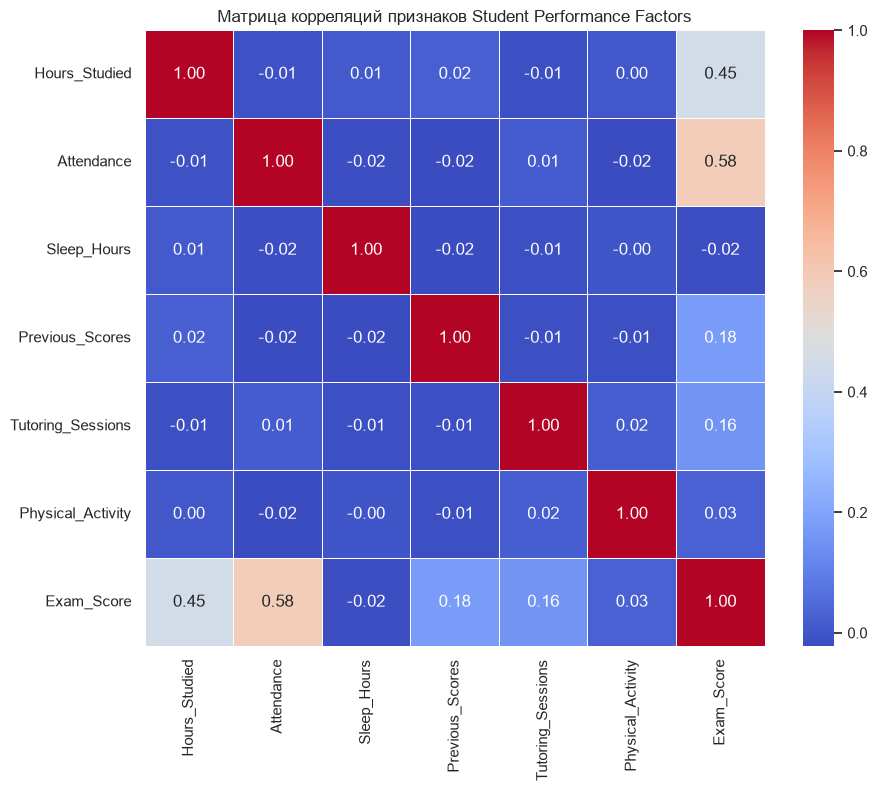

In [35]:
# Ваш код здесь: постройте heatmap корреляционной матрицы
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)
plt.title("Матрица корреляций признаков Student Performance Factors")
plt.show()

*Ваш вывод по heatmap корреляционной матрицы:*
На графике видно, что балл экзамена `Exam_Score` достаточно сильно связан с посещаемостью `Attendance`, и количество часов также уверенно положительно влияет на `Exam_Score` Также можно заметить, что многие признаки связаны слабее, предыдущий балл `Previous_Scores` и количество репетиторских часов `Tutoring_Sessions` не так сильно влияет на оценку экзамена `Exam_Score`.

### **7. Анализ корреляции с итоговым баллом**    

Проанализируйте корреляцию признаков с Exam_Score.

Необходимо:
* отсортировать коэффициенты корреляции;
* определить признаки с наиболее сильной связью;
* построить столбчатую диаграмму.

In [44]:
# Ваш код здесь: отсортируйте коэффициенты корреляции и определите признаки с наиболее сильной связью
corr_with_target = corr_matrix["Exam_Score"].sort_values(ascending=False)
corr_with_target

Exam_Score           1.000000
Attendance           0.581072
Hours_Studied        0.445455
Previous_Scores      0.175079
Tutoring_Sessions    0.156525
Physical_Activity    0.027824
Sleep_Hours         -0.017022
Name: Exam_Score, dtype: float64

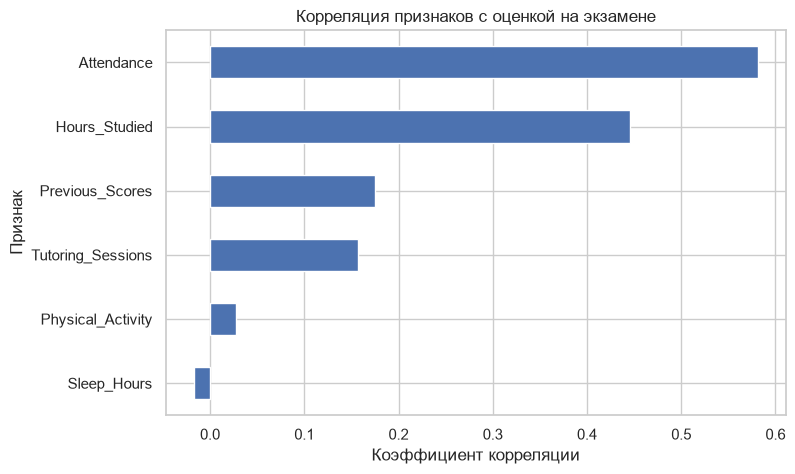

In [45]:
# Ваш код здесь: постройте столбчатую диаграмма
plt.figure(figsize=(8, 5))
corr_with_target.drop("Exam_Score").sort_values().plot(kind="barh")
plt.title("Корреляция признаков с оценкой на экзамене")
plt.xlabel("Коэффициент корреляции")
plt.ylabel("Признак")
plt.show()

*Ваш вывод по признакам и визуализации:*
Как и говорили ранее, наибоее заметная положительная связь между `Exam_Score` - `Attendance` и `Exam_Score`- `Hours_Studied`

### **8. Scatter-графики**
Постройте scatter-графики для следующих пар признаков:
* Hours_Studied и Exam_Score
* Attendance и Exam_Score
* Sleep_Hours и Exam_Score

После каждого графика сделайте краткий вывод.

Hours_Studied и Exam_Score

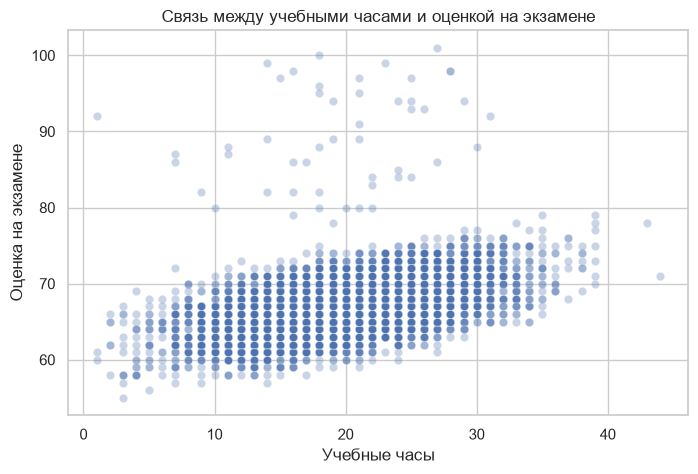

In [46]:
# Ваш код здесь: постройте scatter-график для Hours_Studied и Exam_Score
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="Hours_Studied",
    y="Exam_Score",
    alpha=0.3
)
plt.title("Связь между учебными часами и оценкой на экзамене")
plt.xlabel("Учебные часы")
plt.ylabel("Оценка на экзамене")
plt.show()

*Ваш вывод по визуализации:*

Данные распространены хорошо, границ четко прослежитваются от 0 до 50 часов и от 50 до 102? баллов, есть небольшие выбросы, но четко прослеживается положительный тренд, чем больше часов в среднем тратит студент, тем выше его оценка на экзамене
Корреляция Hours_studied и Exam_score ~ 0.445

Attendance и Exam_Score

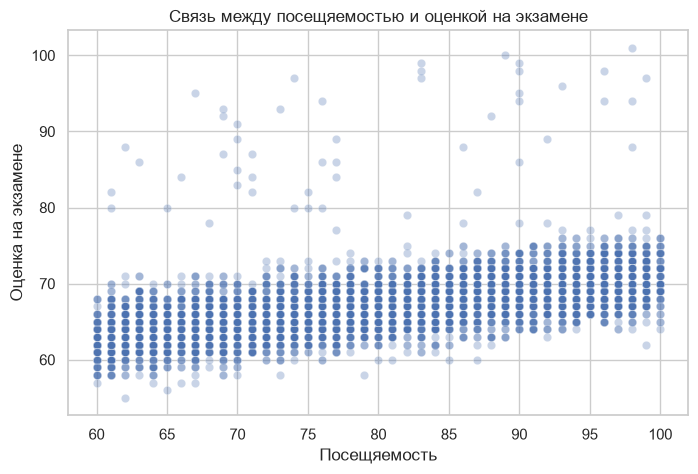

In [48]:
# Ваш код здесь: постройте scatter-график для Attendance и Exam_Score
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="Attendance",
    y="Exam_Score",
    alpha=0.3
)
plt.title("Связь между посещяемостью и оценкой на экзамене")
plt.xlabel("Посещяемость")
plt.ylabel("Оценка на экзамене")
plt.show()

*Ваш вывод по визуализации:*
Данные также распределены равномерно, выбросы присутсвуют, также заметен тренд и корреляция выражена сильнее чем в Attendance и Exam_Score, так как коэффициент корреляции равен 0.58

Sleep_Hours и Exam_Score

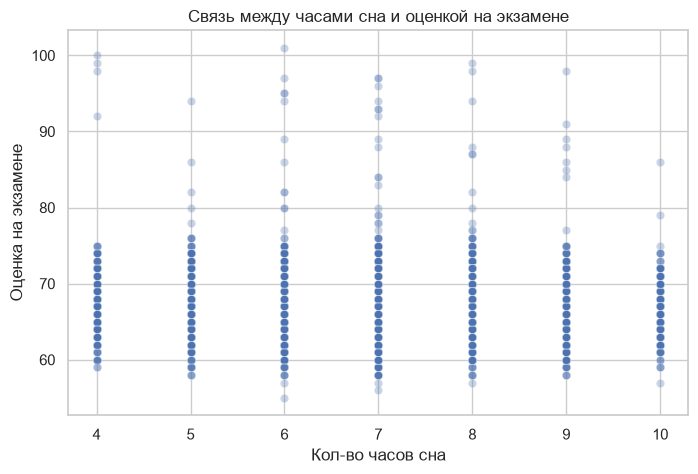

In [49]:
# Ваш код здесь: постройте scatter-график для Sleep_Hours и Exam_Score
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="Sleep_Hours",
    y="Exam_Score",
    alpha=0.3
)
plt.title("Связь между часами сна и оценкой на экзамене")
plt.xlabel("Кол-во часов сна")
plt.ylabel("Оценка на экзамене")
plt.show()

*Ваш вывод по визуализации:*

Данные распределены равномерно, четкой корреляции не прослеживается, больше всего спят по 7-8 часов, но на оценку это не влияет

### **9. Интерпретация коэффициентов корреляции**
Создайте функцию, которая будет интерпретировать силу корреляции.

In [51]:
# Ваш код здесь: создайте функцию, которая будет интерпретировать силу корреляции.
def interpret_corr(value):
    abs_value = abs(value)

    if abs_value >= 0.7:
        strength = "сильная"
    elif abs_value >= 0.4:
        strength = "умеренная"
    elif abs_value >= 0.2:
        strength = "слабая"
    else:
        strength = "очень слабая или почти отсутствующая"

    if value > 0:
        direction = "положительная"
    elif value < 0:
        direction = "отрицательная"
    else:
        direction = "нулевая"

    return f"{strength}, {direction} связь"

In [52]:
# Ваш код здесь: выведите результат применения созданной функции на экран
print("Корреляция между: ")
for feature, value in corr_with_target.drop("Exam_Score").items():
    print(f"Exam_Score и {feature}: {value:.2f} — {interpret_corr(value)}")

Корреляция между: 
Exam_Score и Attendance: 0.58 — умеренная, положительная связь
Exam_Score и Hours_Studied: 0.45 — умеренная, положительная связь
Exam_Score и Previous_Scores: 0.18 — очень слабая или почти отсутствующая, положительная связь
Exam_Score и Tutoring_Sessions: 0.16 — очень слабая или почти отсутствующая, положительная связь
Exam_Score и Physical_Activity: 0.03 — очень слабая или почти отсутствующая, положительная связь
Exam_Score и Sleep_Hours: -0.02 — очень слабая или почти отсутствующая, отрицательная связь


*Ваш вывод по интерпритации полученных результатов:*

По результатам интерпретации видно, что признаки Attendance и Hours_Studied имеют заметную связь с оценкой экзамена — ученики, которые больше ходят на занятия и больше времени учатся обычно имеют более высокую оценку на экзамене. Остальные признаки показывают очень слабую корреляцию, поэтому по ним сложно делать надёжные выводы о влиянии на оценку экзамена.

### **10. Итоговый вывод**

*Ваш итоговый вывод по результатам анализа:*
>
